In [1]:
import torch
from torch import nn
from torchvision.datasets import CIFAR10
from torchvision import transforms
from torch.utils.data import Subset
import cv2
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report
from skimage.feature import hog
from skimage import color
from tqdm import tqdm

In [2]:
seed = 42
np.random.seed(seed)

In [3]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
print(f"device: {device}")

device: cuda


In [4]:
train_dataset = CIFAR10(
    root='../data/datasets/CIFAR10',
    train=True,
    download=True
)

In [5]:
data = train_dataset.data
mean = data.mean(axis=(0, 1, 2)) / 255.0
std = data.std(axis=(0, 1, 2)) / 255.0

In [6]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = CIFAR10(
    root='../data/datasets/CIFAR10',
    train=True,
    transform=transform,
    download=True
)
test_dataset = CIFAR10(
    root='../data/datasets/CIFAR10',
    train=False,
    transform=transform,
    download=False
)

In [7]:
id2label = {i: label for i, label in enumerate(train_dataset.classes)}
label2id = {label: i for i, label in enumerate(train_dataset.classes)}

In [8]:
def get_random_examples(n, dataset):
    idx = np.random.choice(len(test_dataset.targets), size=n, replace=False)
    examples = np.array(test_dataset.data[idx])
    labels = np.array(test_dataset.targets)[idx]
    return examples, labels

In [43]:
def predict_class(model, imgs, transform):
    model.eval()
    with torch.no_grad():
        transform_imgs = torch.stack([transform(img) for img in imgs]).to(device)
        
        outputs = nn.Softmax(dim=1)(model(transform_imgs))
        predict_classes = outputs.argmax(dim=1)
    return predict_classes


def draw_image_predicts(model, imgs, transform, true_classes):
    n = imgs.shape[0]
    cols = 8
    rows = int(torch.ceil(torch.tensor(n / cols)).item())
    classes = predict_class(model, imgs, transform).cpu()
    pred_labels = [id2label[i.item()] for i in classes]
    true_labels = [id2label[i] for i in true_classes]
    

    fig, axis = plt.subplots(rows, cols, figsize=(5*cols, 7*rows))
    axis = axis.flatten()

    for i in range(n):
        ax = axis[i]
        ax.imshow(imgs[i])
        ax.set_title(f'True: {true_labels[i]}\nPredict: {pred_labels[i]}', fontsize=30)
        ax.axis('off')

    for j in range(i+1, len(axis)):
        axis[j].axis('off')

    plt.tight_layout()

def draw_image_2(model, imgs, imgs_transform, true_classes):
    n = imgs.shape[0]
    cols = 8
    rows = int(torch.ceil(torch.tensor(n / cols)).item())
    classes = model.predict(imgs_transform)
    pred_labels = [id2label[i.item()] for i in classes]
    true_labels = [id2label[i] for i in true_classes]
    

    fig, axis = plt.subplots(rows, cols, figsize=(5*cols, 7*rows))
    axis = axis.flatten()

    for i in range(n):
        ax = axis[i]
        ax.imshow(imgs[i])
        ax.set_title(f'True: {true_labels[i]}\nPredict: {pred_labels[i]}', fontsize=30)
        ax.axis('off')

    for j in range(i+1, len(axis)):
        axis[j].axis('off')

    plt.tight_layout()

In [10]:
def train_loop(model, loss, optimizer, dataloader, train_losses):
    model.train()
    batch_losses = []
    all_targets = []
    all_predictions = []
    
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        y_pred = model(X)
        output = loss(y_pred, y)
        batch_losses.append(output.item())
        output.backward()
        optimizer.step()

        all_predictions.extend(torch.argmax(y_pred, dim=1).cpu().tolist())
        all_targets.extend(y.cpu().tolist())

        if batch % 100 == 0:
            print(f'{(batch + 1) * dataloader.batch_size}/{len(dataloader) * dataloader.batch_size} | loss: {output.item()}')

    train_losses.append(sum(batch_losses) / len(batch_losses))

In [11]:
def test_loop(model, loss, dataloader, test_losses):
    model.eval()
    batch_losses = []
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
    
            y_pred = model(X)
            output = loss(y_pred, y)
            batch_losses.append(output.item())

    
            all_predictions.extend(torch.argmax(y_pred, dim=1).cpu().tolist())
            all_targets.extend(y.cpu().tolist())
    
        avg_loss = sum(batch_losses) / len(batch_losses)
        
        print(f'{"Test loss:":11} {avg_loss:.4f}')
        print(classification_report(all_targets, all_predictions))

    test_losses.append(sum(batch_losses) / len(batch_losses))

In [12]:
def train_test_loss_plot(train_losses, test_losses):
    plt.plot(range(1, num_epochs+1), train_losses, label='train loss')
    plt.plot(range(1, num_epochs+1), test_losses, label='test loss')
    plt.legend()
    plt.grid(alpha=0.6)
    plt.xlabel('epoch')
    plt.ylabel('loss')

In [13]:
def extract_hist_features(dataset):
    hist_features = []
    labels = []
    
    for i in tqdm(range(len(dataset))):
        img_pil, label = dataset[i]
        
              
        hist_features.append(hist_transform_func(img_pil))
        labels.append(label)
    
    return np.array(hist_features), np.array(labels)

def hist_transform_func(img):
    img_tensor = torch.tensor(np.array(img)).float() / 255.0
    img_tensor = img_tensor.permute(2, 0, 1)
    
    hists = []
    for j in range(3):
        hist = torch.histc(img_tensor[j], bins=256, min=0, max=1)
        hists.append(hist)
    return torch.cat(hists)

In [14]:
def extract_hog_features(dataset, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):
    hog_features = []
    labels = []
    
    for i in tqdm(range(len(dataset))):
        img_pil, label = dataset[i]
        
        img_np = np.array(img_pil)
        feat = hog_transform_func(img_np)
        hog_features.append(feat)
        labels.append(label)
    
    return np.array(hog_features), np.array(labels)

def hog_transform_func(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):  
    img_gray = color.rgb2gray(img)
    
    feat = hog(img_gray, 
               orientations=orientations, 
               pixels_per_cell=pixels_per_cell,
               cells_per_block=cells_per_block, 
               block_norm='L2-Hys')
    
    return torch.tensor(feat).float()

In [15]:
train_data = CIFAR10(root='../data/datasets/CIFAR10', train=True, download=True)
test_data = CIFAR10(root='../data/datasets/CIFAR10', train=False, download=True)

In [16]:
X_train_hist, y_train_hist = extract_hist_features(train_data)
X_test_hist, y_test_hist = extract_hist_features(test_data)

100%|███████████████████████████████████████████████████████████████████████████| 10000/10000 [00:10<00:00, 958.80it/s]


In [17]:
X_train_hog, y_train_hog = extract_hog_features(train_data)
X_test_hog, y_test_hog = extract_hog_features(test_data)

100%|███████████████████████████████████████████████████████████████████████████| 10000/10000 [00:15<00:00, 641.50it/s]


In [18]:
def data_to_dataloader(X_train, X_test, y_train, y_test, batch_size=128):
    X_train_tensor = torch.from_numpy(X_train).float()
    y_train_tensor = torch.from_numpy(y_train).long()
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    
    X_test_tensor = torch.from_numpy(X_test).float()
    y_test_tensor = torch.from_numpy(y_test).long()
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

    return DataLoader(train_dataset, batch_size=batch_size), DataLoader(test_dataset, batch_size=batch_size)

In [19]:
n = 16
examples, true_labels = get_random_examples(n, train_dataset)

# Задание 1. Old School Image Classification

In [20]:
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

In [21]:
scaler = StandardScaler()
X_train_hist_scaled = scaler.fit_transform(X_train_hist)
X_test_hist_scaled = scaler.transform(X_test_hist)

scaler_2 = StandardScaler()
X_train_hog_scaled = scaler_2.fit_transform(X_train_hog)
X_test_hog_scaled = scaler_2.transform(X_test_hog)

## Входные данные: гистограммы

### KNN

In [22]:
k_neighbors = 5
knn_hist = KNeighborsClassifier(k_neighbors).fit(X_train_hist_scaled, y_train_hist)
pred_knn_hist = knn_hist.predict(X_test_hist_scaled)
print(classification_report(y_test_hist, pred_knn_hist))

              precision    recall  f1-score   support

           0       0.35      0.39      0.37      1000
           1       0.26      0.40      0.31      1000
           2       0.25      0.27      0.26      1000
           3       0.19      0.22      0.20      1000
           4       0.31      0.29      0.30      1000
           5       0.24      0.17      0.20      1000
           6       0.28      0.43      0.34      1000
           7       0.30      0.16      0.21      1000
           8       0.37      0.27      0.32      1000
           9       0.34      0.23      0.27      1000

    accuracy                           0.28     10000
   macro avg       0.29      0.28      0.28     10000
weighted avg       0.29      0.28      0.28     10000



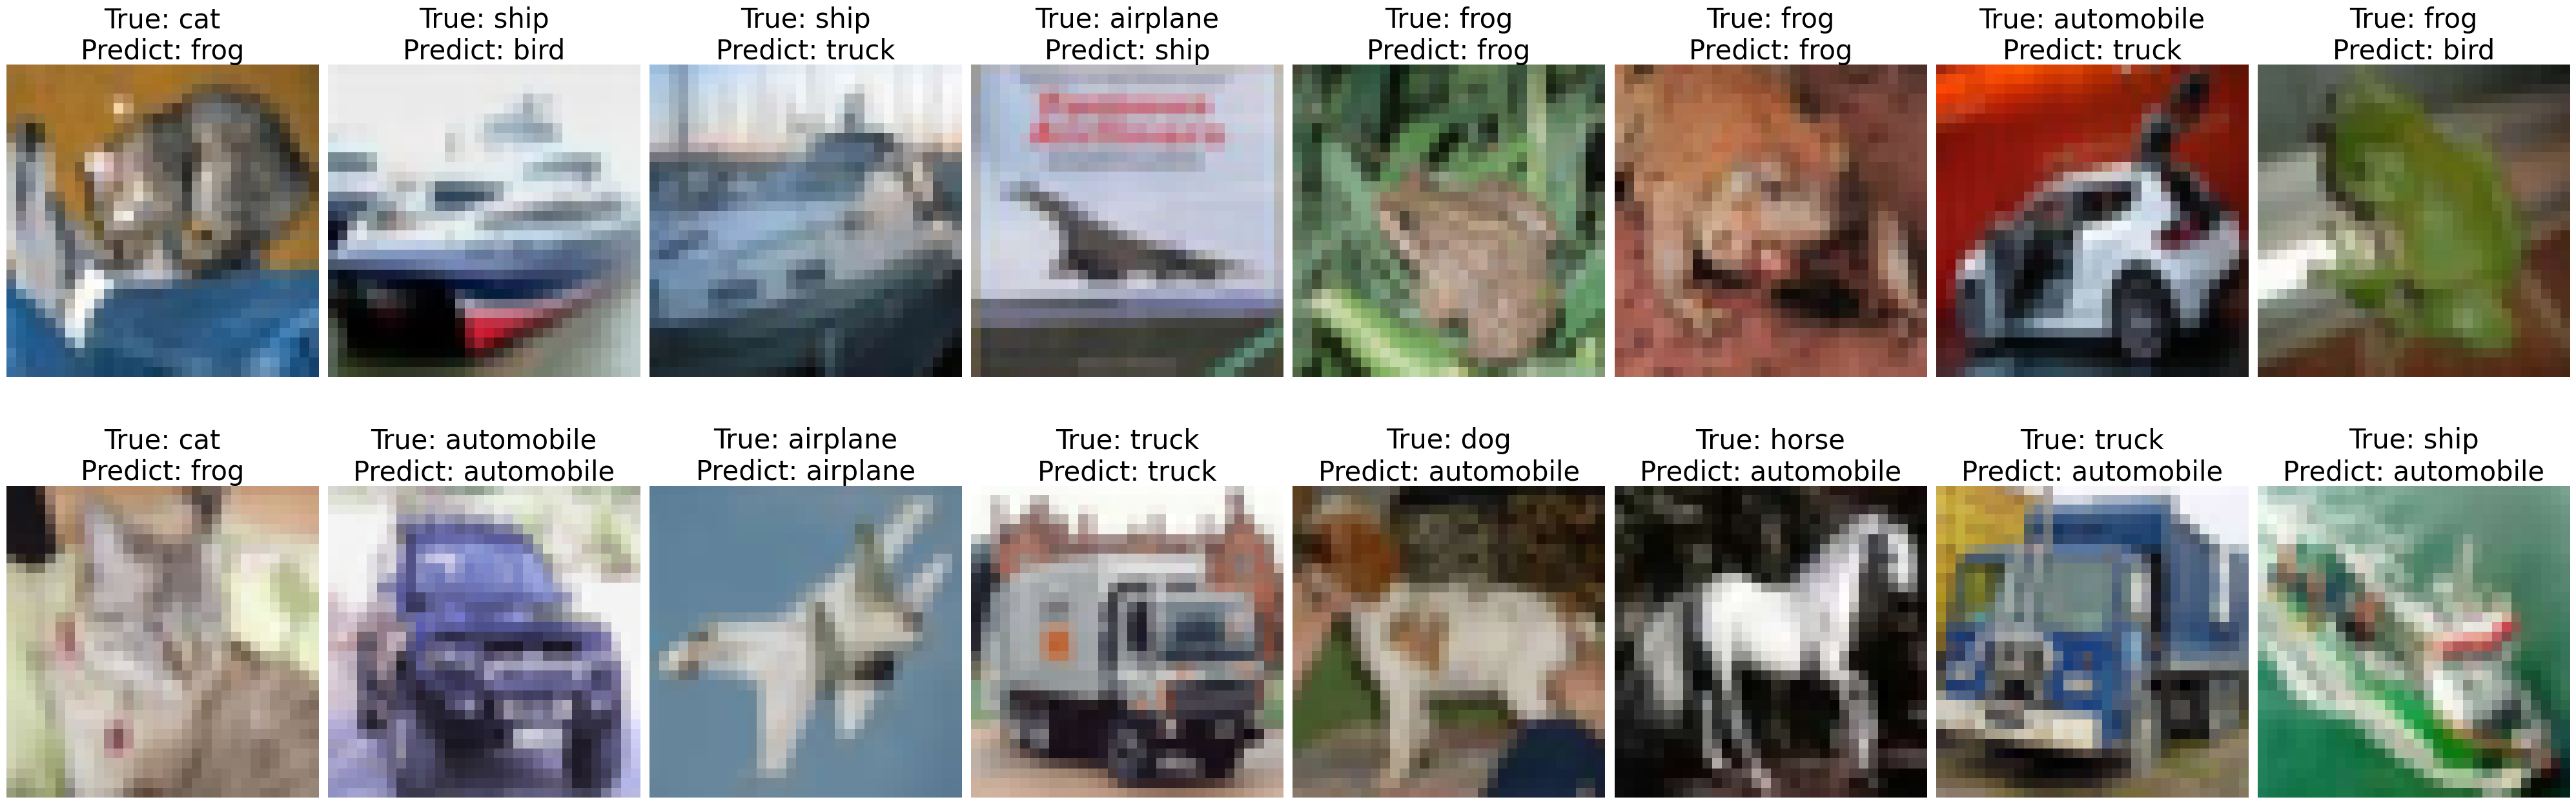

In [58]:
draw_image_2(knn_hist, np.array([test_data[i][0] for i in range(16)]), X_test_hist_scaled[:16], y_test_hist[:16])

### Логистическая регрессия

In [60]:
lr_hist = LogisticRegression(solver='newton-cg').fit(X_train_hist_scaled, y_train_hist)
pred_lr_hist = lr_hist.predict(X_test_hist_scaled)
print(classification_report(y_test_hist, pred_lr_hist))

              precision    recall  f1-score   support

           0       0.31      0.36      0.33      1000
           1       0.22      0.22      0.22      1000
           2       0.15      0.12      0.13      1000
           3       0.19      0.16      0.17      1000
           4       0.26      0.32      0.29      1000
           5       0.19      0.17      0.18      1000
           6       0.28      0.36      0.32      1000
           7       0.22      0.14      0.17      1000
           8       0.28      0.37      0.32      1000
           9       0.23      0.21      0.22      1000

    accuracy                           0.24     10000
   macro avg       0.23      0.24      0.23     10000
weighted avg       0.23      0.24      0.23     10000



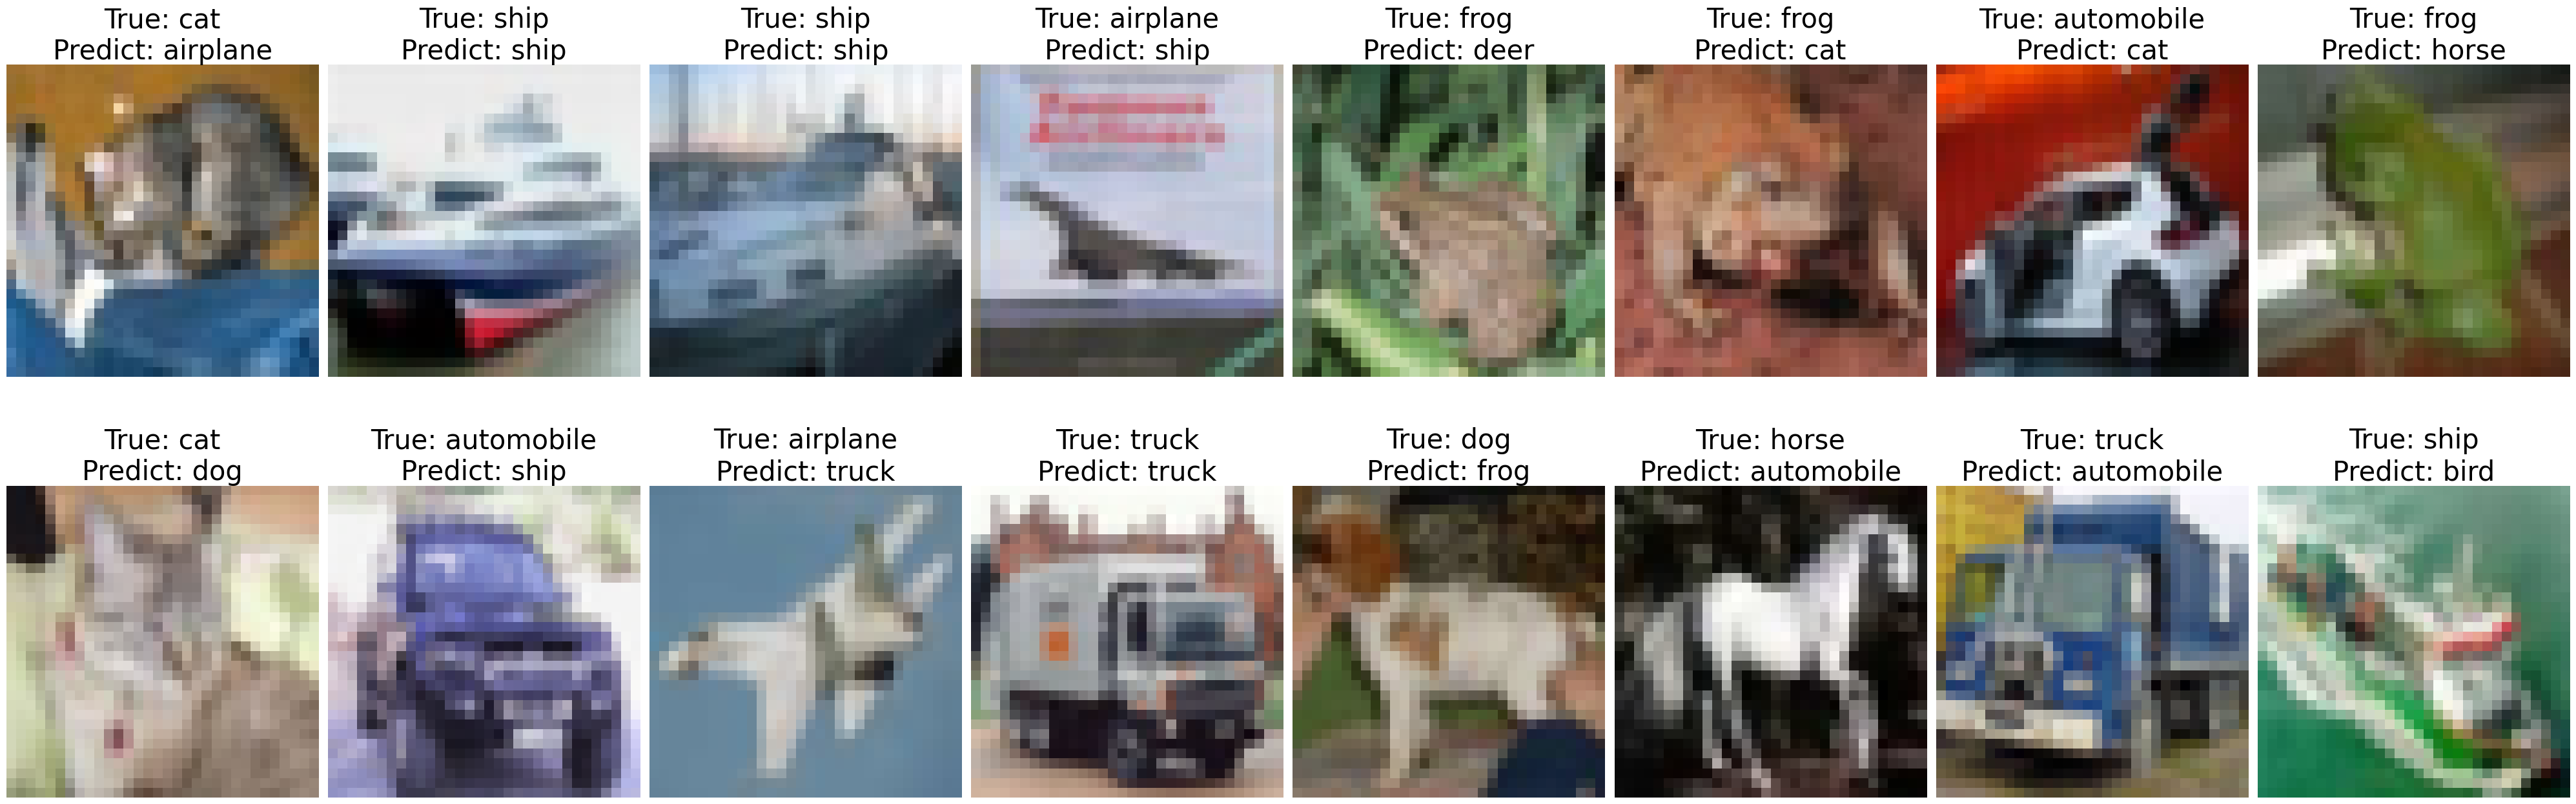

In [61]:
draw_image_2(lr_hist, np.array([test_data[i][0] for i in range(16)]), X_test_hist_scaled[:16], y_test_hist[:16])

### CatBoost

In [62]:
cb_hist = CatBoostClassifier(
    iterations=2000,
    loss_function='MultiClass',
    eval_metric='TotalF1',
    task_type='GPU',
    random_seed=seed
)

cb_hist.fit(
    X_train_hist_scaled, 
    y_train_hist, 
    use_best_model=True,
    eval_set=(X_test_hist_scaled, y_test_hist),
    verbose=100,
    early_stopping_rounds=100,
)
pred_cb_hist = cb_hist.predict(X_test_hist_scaled)
print(classification_report(y_test_hist, pred_cb_hist))

Learning rate set to 0.115313
0:	learn: 0.2015186	test: 0.2003246	best: 0.2003246 (0)	total: 308ms	remaining: 10m 15s
100:	learn: 0.3896386	test: 0.3263630	best: 0.3269052 (99)	total: 5.9s	remaining: 1m 50s
200:	learn: 0.4375768	test: 0.3456810	best: 0.3469153 (199)	total: 10.9s	remaining: 1m 37s
300:	learn: 0.4670308	test: 0.3525598	best: 0.3540403 (278)	total: 15.5s	remaining: 1m 27s
400:	learn: 0.4897463	test: 0.3569281	best: 0.3580483 (393)	total: 20.1s	remaining: 1m 20s
500:	learn: 0.5078563	test: 0.3593179	best: 0.3607222 (465)	total: 24.6s	remaining: 1m 13s
600:	learn: 0.5265666	test: 0.3656238	best: 0.3661848 (588)	total: 29s	remaining: 1m 7s
700:	learn: 0.5420353	test: 0.3654735	best: 0.3669408 (644)	total: 33.5s	remaining: 1m 2s
800:	learn: 0.5574730	test: 0.3655055	best: 0.3679125 (719)	total: 37.8s	remaining: 56.6s
bestTest = 0.3679125309
bestIteration = 719
Shrink model to first 720 iterations.
              precision    recall  f1-score   support

           0       0.46 

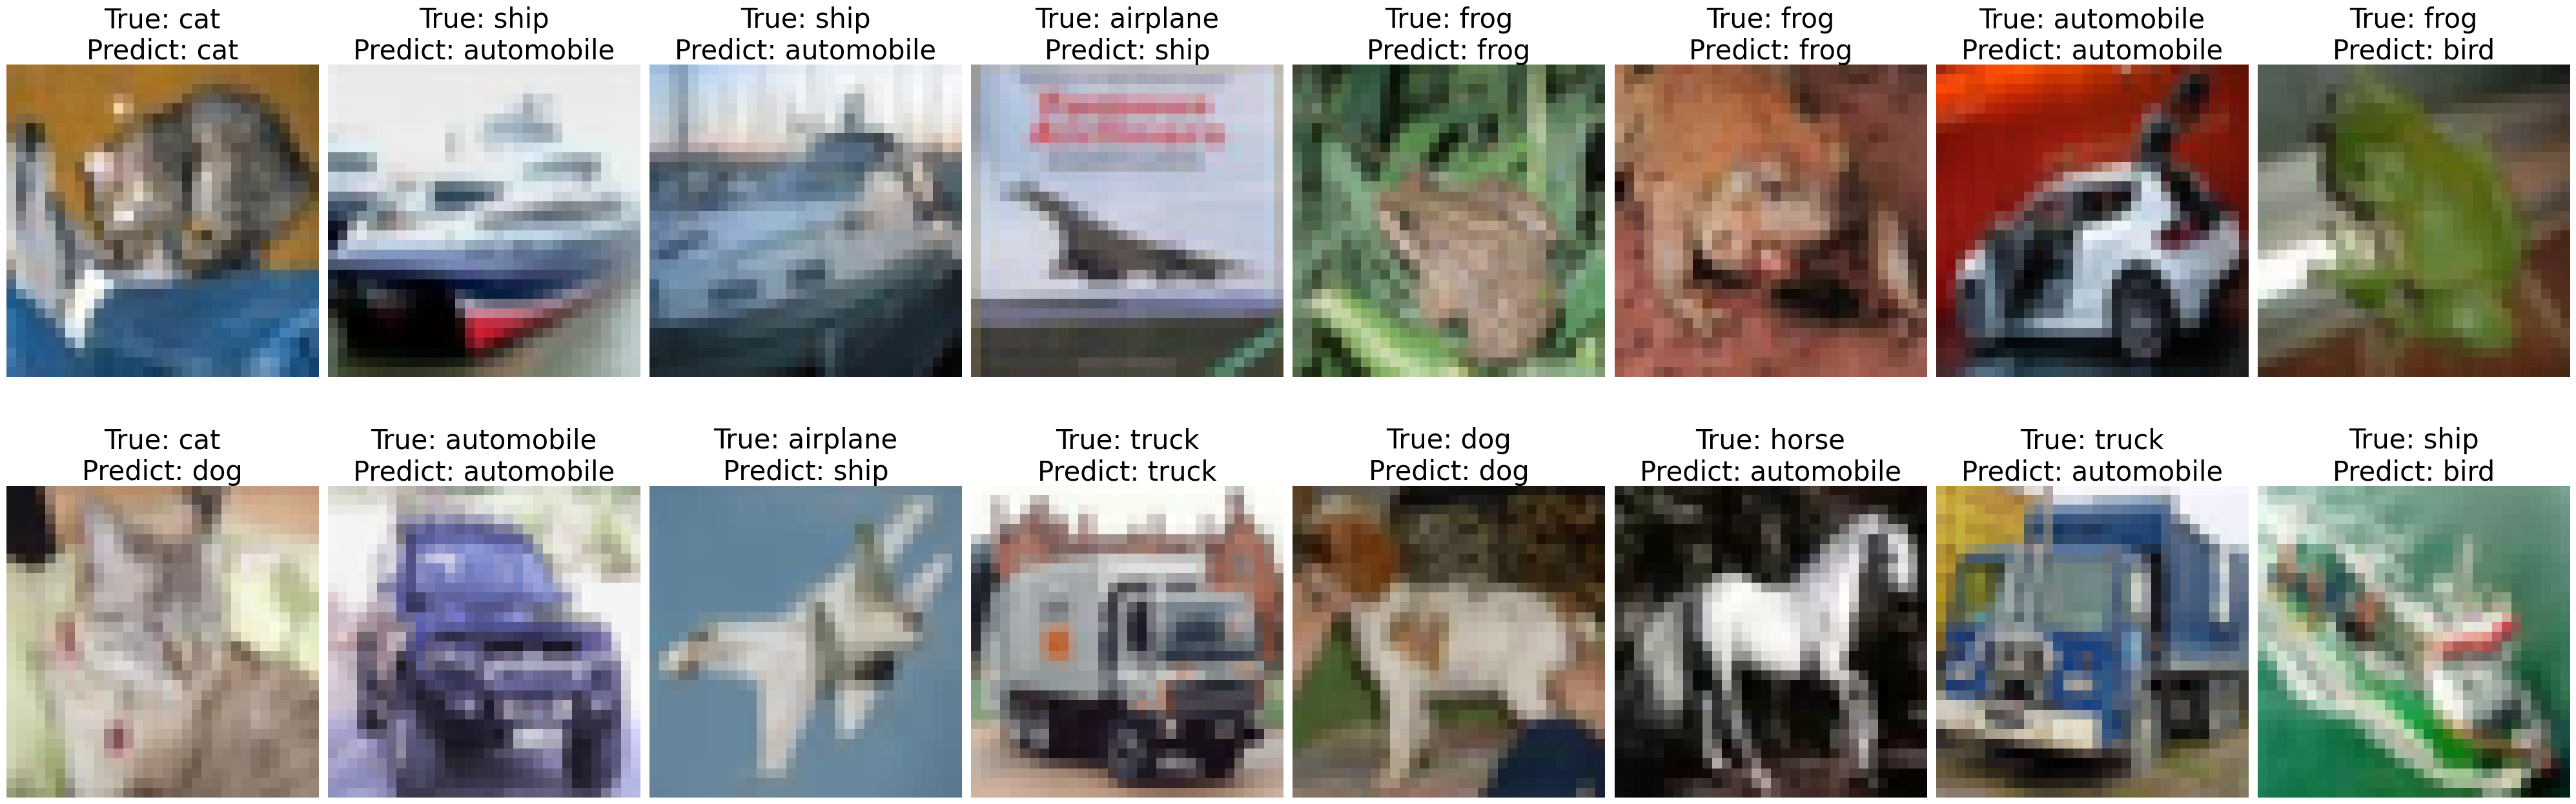

In [63]:
draw_image_2(cb_hist, np.array([test_data[i][0] for i in range(16)]), X_test_hist_scaled[:16], y_test_hist[:16])

## Входные данные: HOG

### KNN

In [64]:
k_neighbors = 5
knn_hog = KNeighborsClassifier(k_neighbors).fit(X_train_hog_scaled, y_train_hog)
pred_knn_hog = knn_hog.predict(X_test_hog_scaled)
print(classification_report(y_test_hog, pred_knn_hog))

              precision    recall  f1-score   support

           0       0.63      0.51      0.56      1000
           1       0.64      0.69      0.66      1000
           2       0.43      0.36      0.39      1000
           3       0.43      0.19      0.26      1000
           4       0.30      0.61      0.40      1000
           5       0.47      0.28      0.35      1000
           6       0.37      0.75      0.50      1000
           7       0.71      0.42      0.53      1000
           8       0.65      0.55      0.59      1000
           9       0.67      0.49      0.57      1000

    accuracy                           0.48     10000
   macro avg       0.53      0.48      0.48     10000
weighted avg       0.53      0.48      0.48     10000



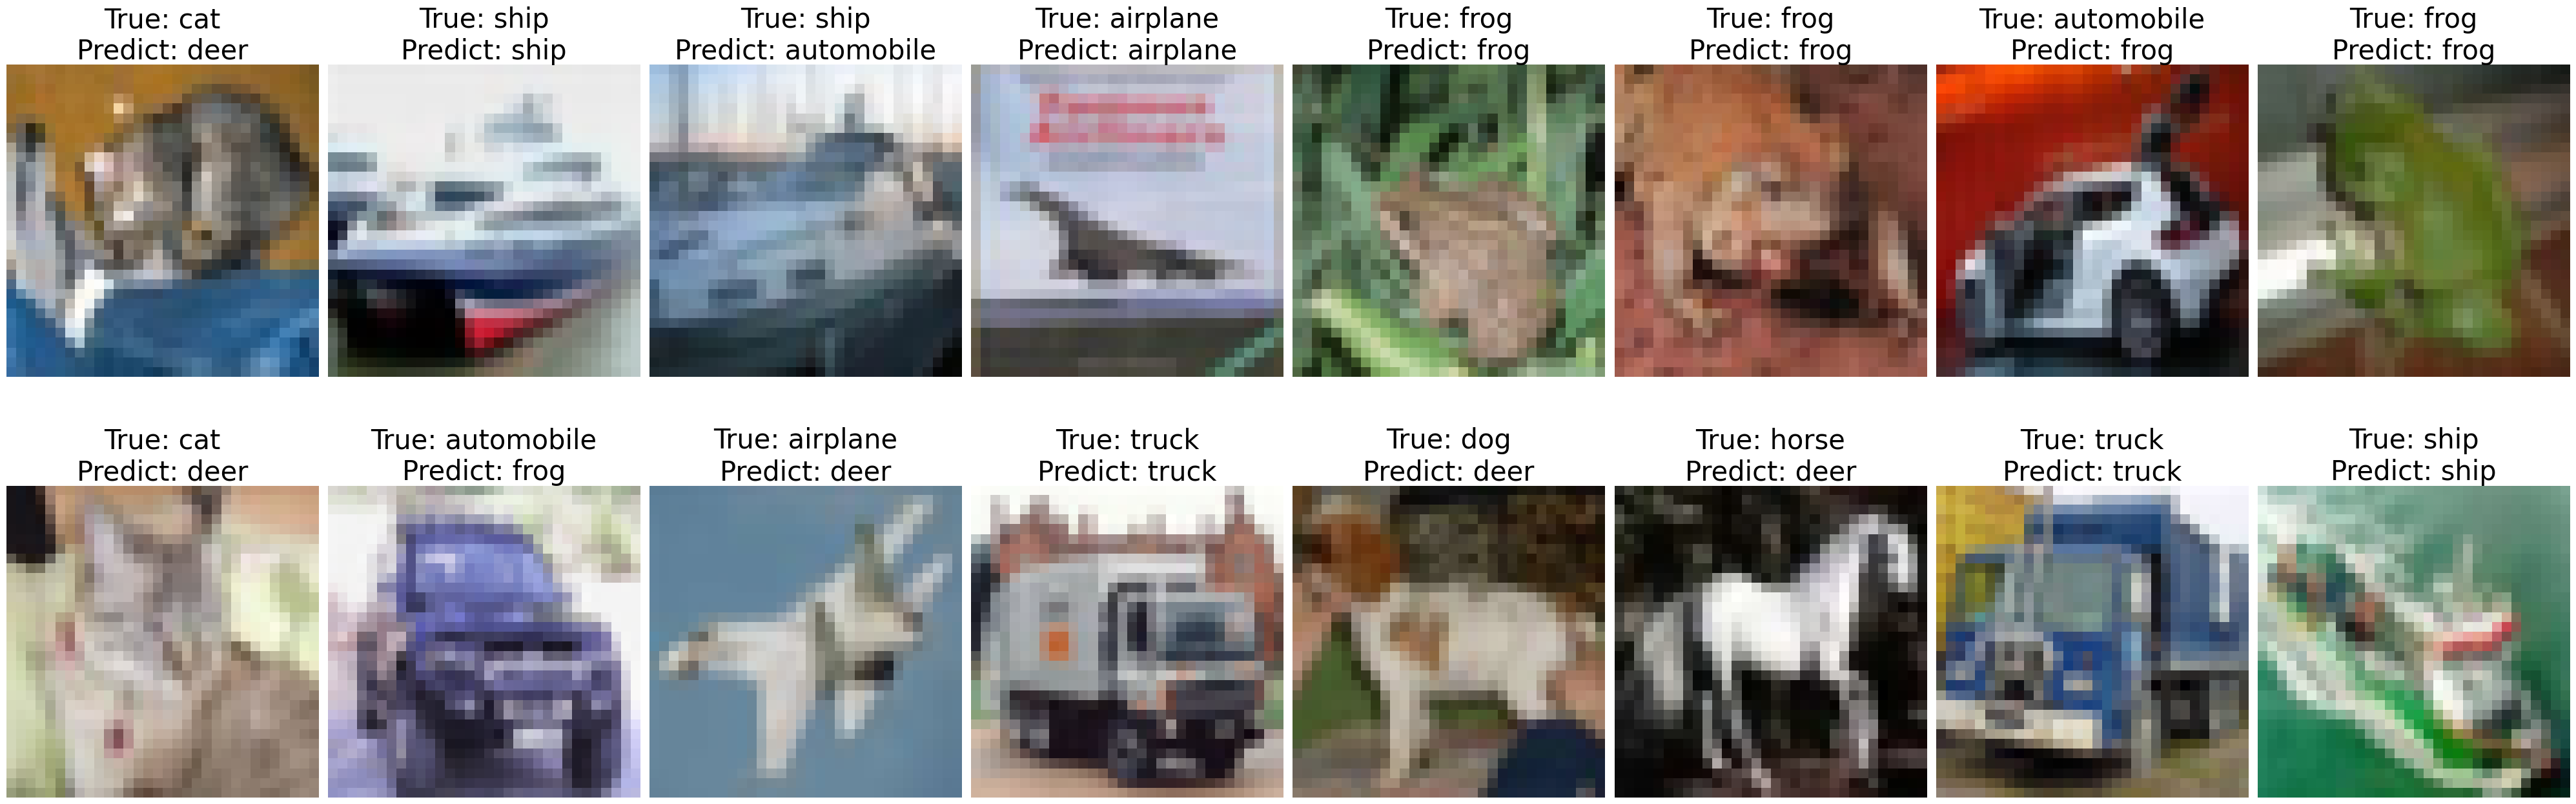

In [65]:
draw_image_2(knn_hog, np.array([test_data[i][0] for i in range(16)]), X_test_hog_scaled[:16], y_test_hog[:16])

### Логистическая регрессия

In [67]:
lr_hog = LogisticRegression(solver='newton-cg').fit(X_train_hog_scaled, y_train_hog)
pred_lr_hog = lr_hog.predict(X_test_hog_scaled)
print(classification_report(y_test_hog, pred_lr_hog))

              precision    recall  f1-score   support

           0       0.59      0.58      0.59      1000
           1       0.60      0.62      0.61      1000
           2       0.45      0.39      0.42      1000
           3       0.40      0.31      0.35      1000
           4       0.43      0.46      0.45      1000
           5       0.44      0.43      0.43      1000
           6       0.51      0.62      0.56      1000
           7       0.57      0.57      0.57      1000
           8       0.56      0.57      0.57      1000
           9       0.62      0.64      0.63      1000

    accuracy                           0.52     10000
   macro avg       0.52      0.52      0.52     10000
weighted avg       0.52      0.52      0.52     10000



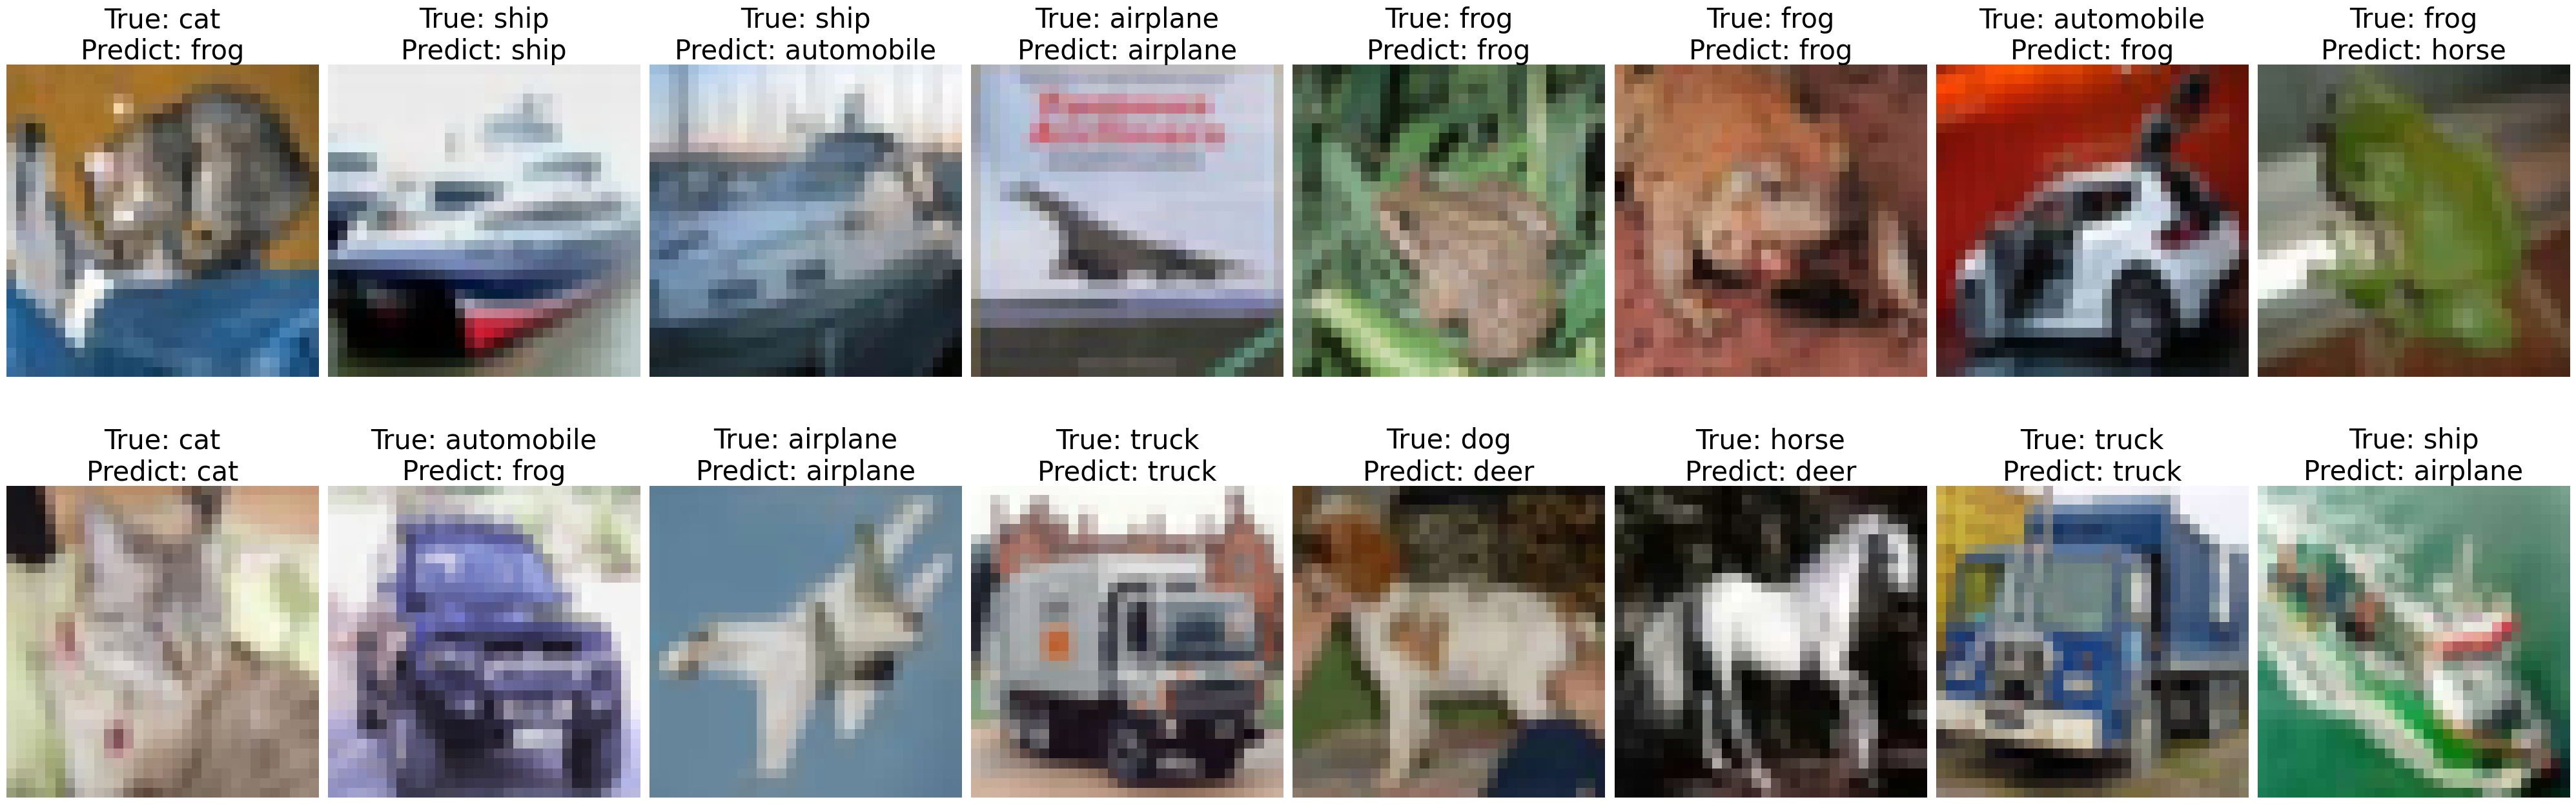

In [68]:
draw_image_2(lr_hog, np.array([test_data[i][0] for i in range(16)]), X_test_hog_scaled[:16], y_test_hog[:16])

### CatBoost

In [69]:
cb_hog = CatBoostClassifier(
    iterations=2000,
    loss_function='MultiClass',
    eval_metric='TotalF1',
    task_type='GPU',
    random_seed=seed
)

cb_hog.fit(
    X_train_hog_scaled, 
    y_train_hog, 
    use_best_model=True,
    eval_set=(X_test_hog_scaled, y_test_hog),
    verbose=100,
    early_stopping_rounds=100,
)
pred_cb_hog = cb_hog.predict(X_test_hog_scaled)
print(classification_report(y_test_hog, pred_cb_hog))

Learning rate set to 0.115313
0:	learn: 0.2266645	test: 0.2221219	best: 0.2221219 (0)	total: 50.7ms	remaining: 1m 41s
100:	learn: 0.5792209	test: 0.5252085	best: 0.5252085 (100)	total: 4.19s	remaining: 1m 18s
200:	learn: 0.6476946	test: 0.5620603	best: 0.5622461 (198)	total: 8.12s	remaining: 1m 12s
300:	learn: 0.6980388	test: 0.5796194	best: 0.5803412 (297)	total: 12.1s	remaining: 1m 8s
400:	learn: 0.7372977	test: 0.5885833	best: 0.5893577 (399)	total: 16.1s	remaining: 1m 4s
500:	learn: 0.7704949	test: 0.5965060	best: 0.5965243 (472)	total: 20.1s	remaining: 1m
600:	learn: 0.8018113	test: 0.6012171	best: 0.6012171 (600)	total: 24.2s	remaining: 56.3s
700:	learn: 0.8288844	test: 0.6042023	best: 0.6044167 (699)	total: 28.2s	remaining: 52.2s
800:	learn: 0.8532558	test: 0.6026556	best: 0.6051333 (703)	total: 32.2s	remaining: 48.2s
bestTest = 0.6051333282
bestIteration = 703
Shrink model to first 704 iterations.
              precision    recall  f1-score   support

           0       0.66   

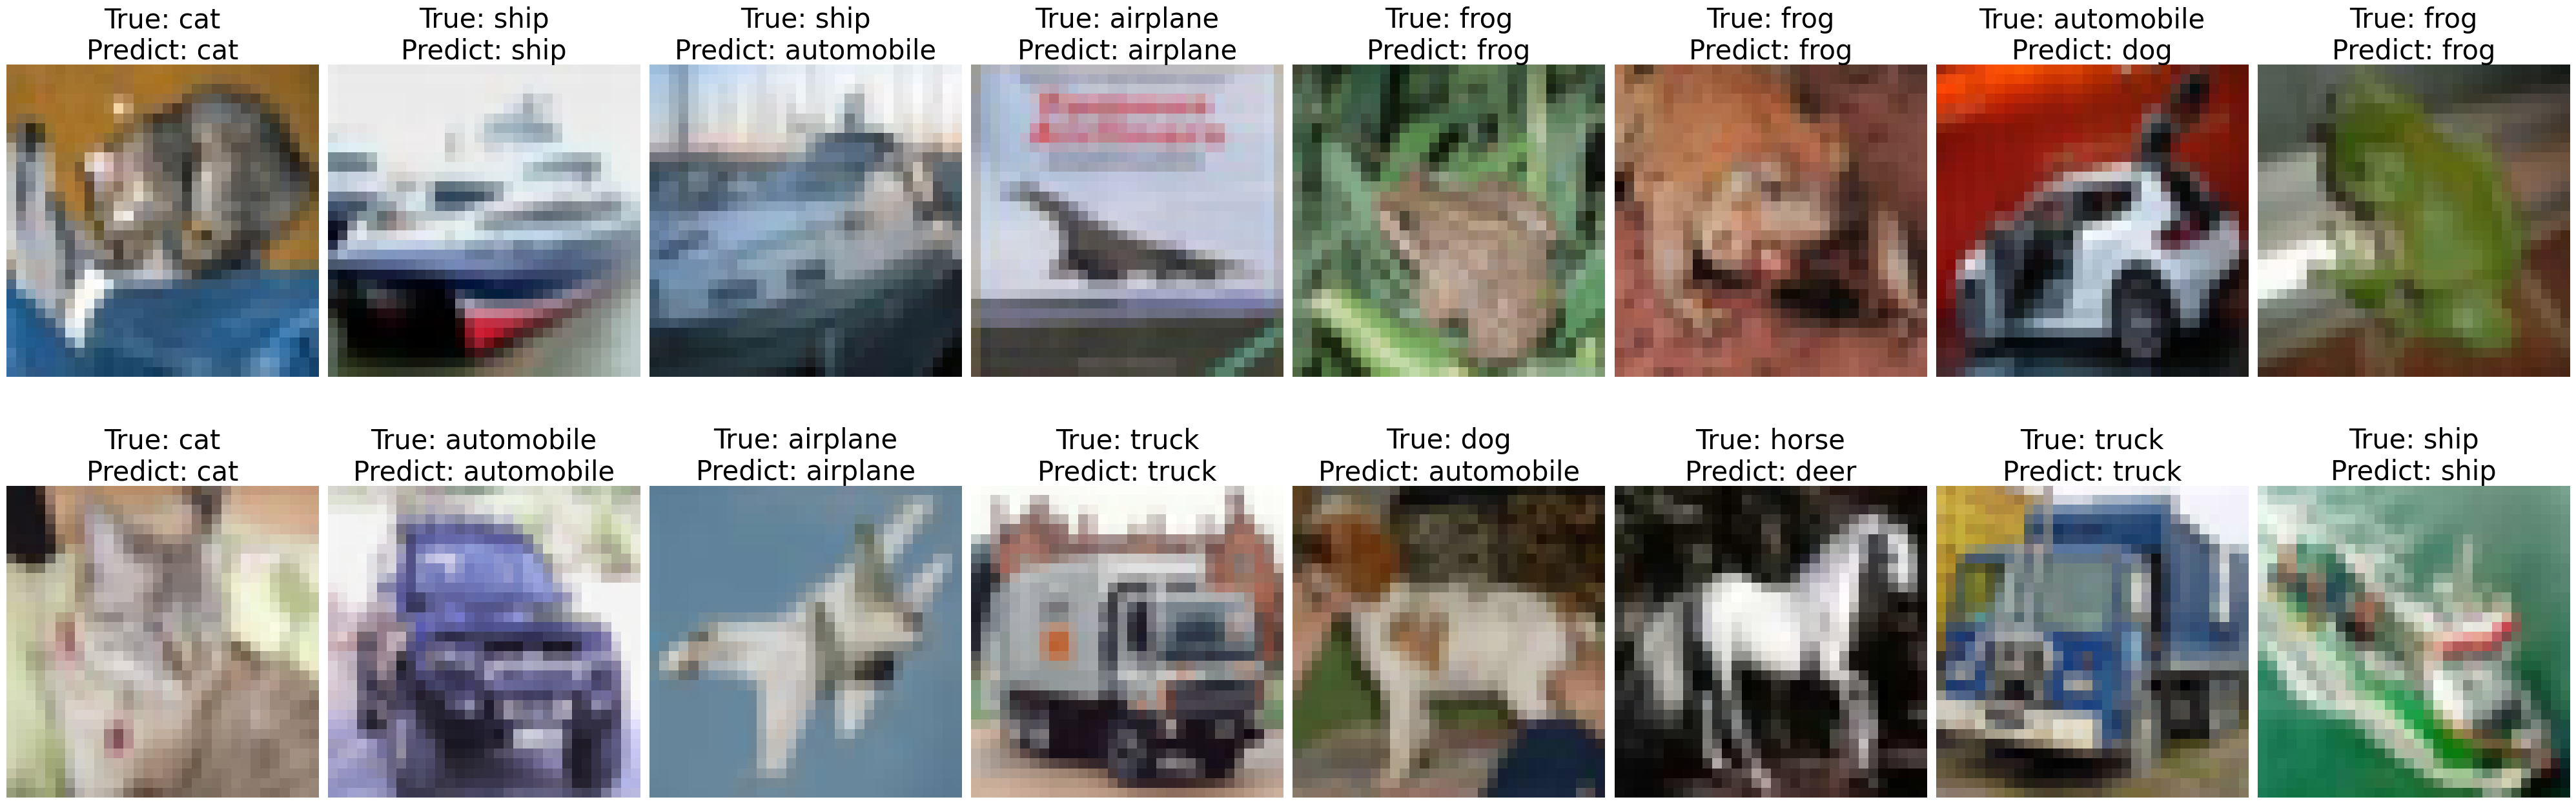

In [70]:
draw_image_2(cb_hog, np.array([test_data[i][0] for i in range(16)]), X_test_hog_scaled[:16], y_test_hog[:16])

# Задание 2. Классификация изображений полносвязной нейронной сетью

## Входные данные: пиксели

In [28]:
class ClassificationModel(nn.Module):
    def __init__(self, h=32, w=32, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(3 * h * w, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [29]:
batch_size = 128
train_dataloader = DataLoader(train_dataset, batch_size)
test_dataloader = DataLoader(test_dataset, batch_size)

In [30]:
model = ClassificationModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)
train_losses_fc = []
test_losses_fc = []

In [31]:
num_epochs = 20

In [32]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(model, loss_fn, optimizer, train_dataloader, train_losses_fc)
    test_loop(model, loss_fn, test_dataloader, test_losses_fc)
    print('-' * 30)

Epoch 1
128/50048 | loss: 2.530693531036377
12928/50048 | loss: 1.8773016929626465
25728/50048 | loss: 1.7966721057891846
38528/50048 | loss: 1.7292180061340332
Test loss:  1.6579
              precision    recall  f1-score   support

           0       0.51      0.51      0.51      1000
           1       0.51      0.46      0.48      1000
           2       0.33      0.28      0.30      1000
           3       0.33      0.23      0.27      1000
           4       0.38      0.35      0.36      1000
           5       0.35      0.37      0.36      1000
           6       0.40      0.54      0.46      1000
           7       0.46      0.40      0.43      1000
           8       0.49      0.61      0.55      1000
           9       0.46      0.52      0.49      1000

    accuracy                           0.43     10000
   macro avg       0.42      0.43      0.42     10000
weighted avg       0.42      0.43      0.42     10000

------------------------------
Epoch 2
128/50048 | loss: 1.69

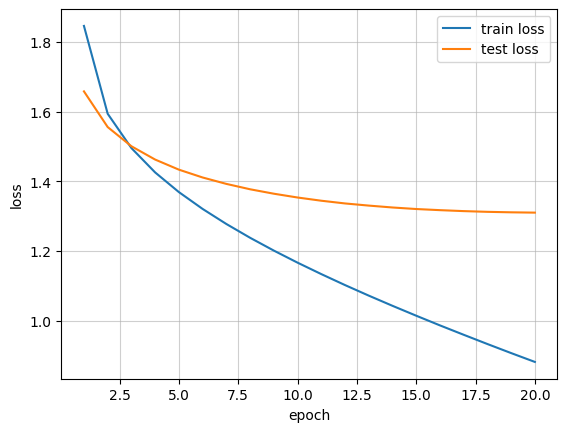

In [33]:
train_test_loss_plot(train_losses_fc, test_losses_fc)

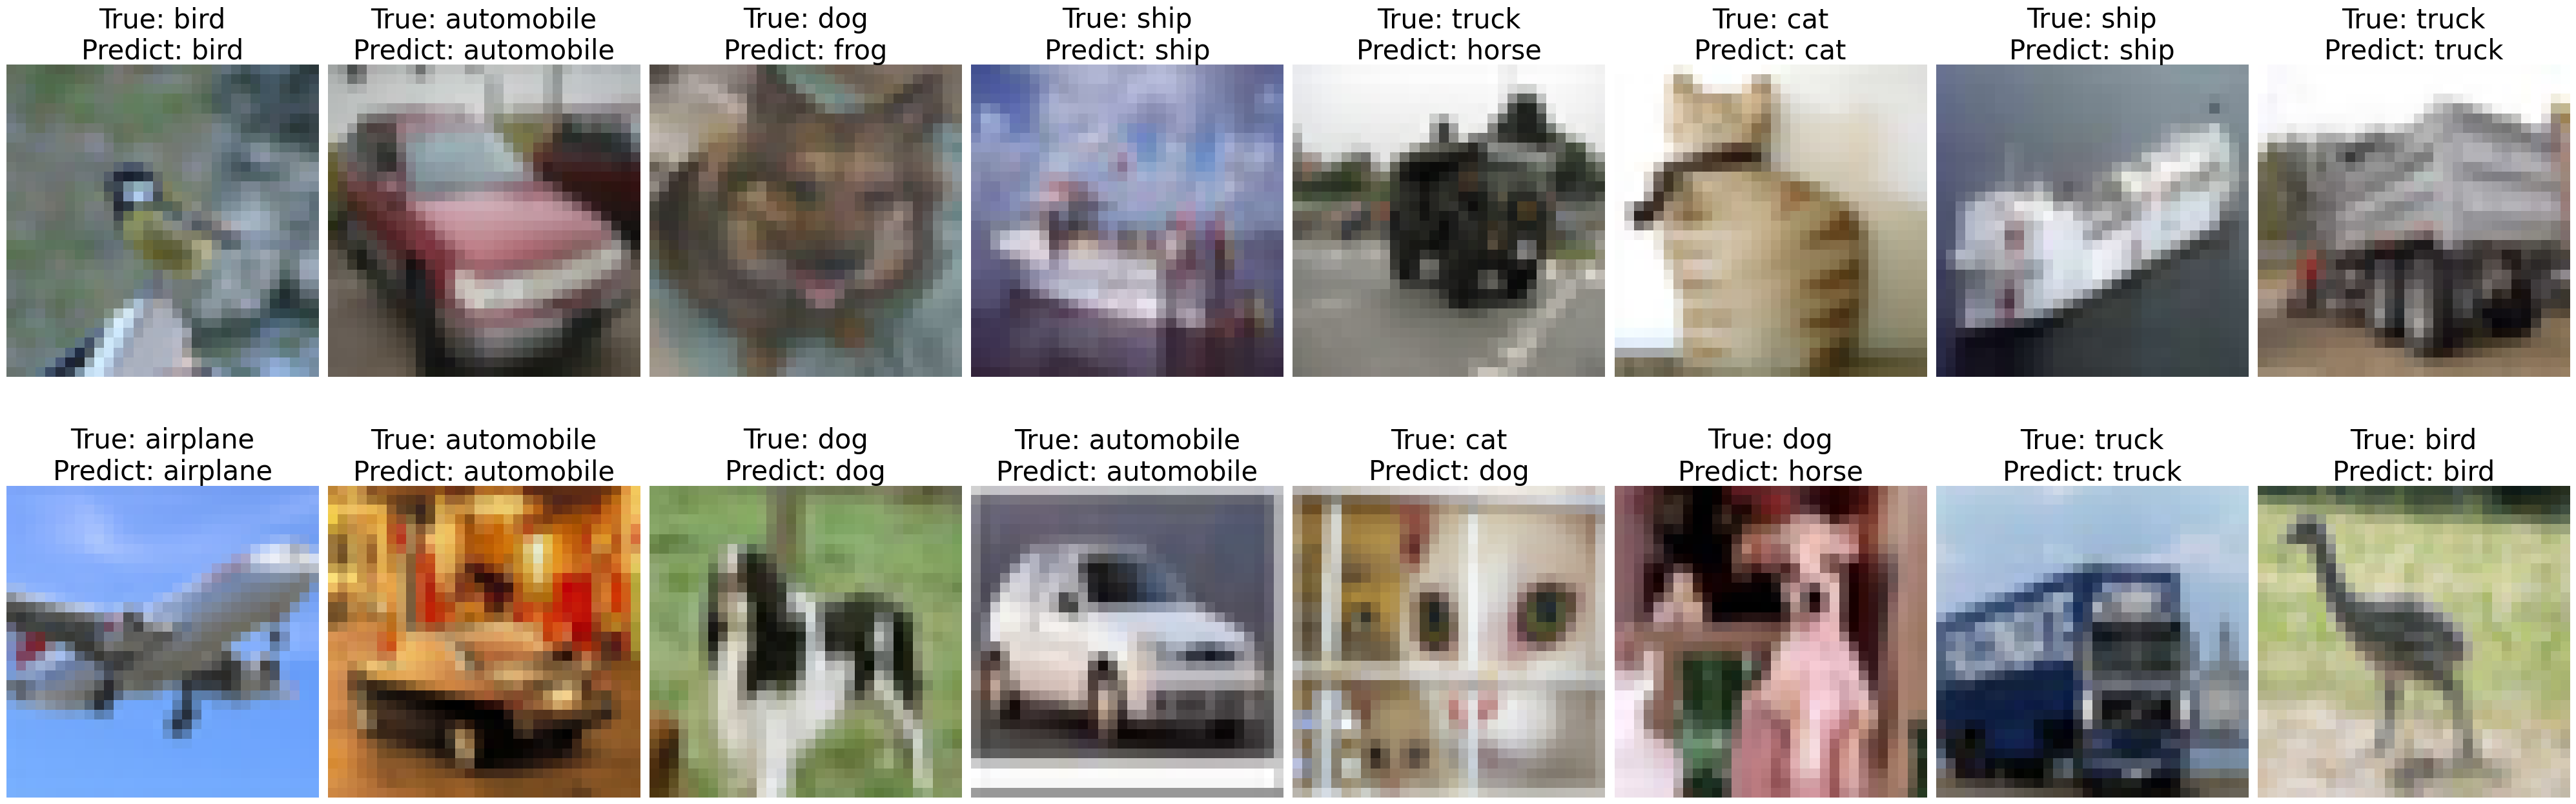

In [34]:
draw_image_predicts(model, examples, transform, true_labels)

## Входные данные: гистограммы

In [35]:
batch_size = 128
train_hist_dataloader, test_hist_dataloader = data_to_dataloader(X_train_hist, X_test_hist, y_train_hist, y_test_hist, batch_size)

In [36]:
class ClassificationHistModel(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(768, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits

In [37]:
hist_model = ClassificationHistModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(hist_model.parameters(), lr=1e-5)
train_losses_hist = []
test_losses_hist = []

In [38]:
num_epochs = 20

In [39]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(hist_model, loss_fn, optimizer, train_hist_dataloader, train_losses_hist)
    test_loop(hist_model, loss_fn, test_hist_dataloader, test_losses_hist)
    print('-' * 30)

Epoch 1
128/50048 | loss: 2.37923526763916
12928/50048 | loss: 2.1584596633911133
25728/50048 | loss: 2.1695404052734375
38528/50048 | loss: 2.0204687118530273
Test loss:  2.0331
              precision    recall  f1-score   support

           0       0.34      0.41      0.37      1000
           1       0.25      0.27      0.26      1000
           2       0.27      0.16      0.20      1000
           3       0.20      0.10      0.14      1000
           4       0.27      0.33      0.30      1000
           5       0.19      0.12      0.14      1000
           6       0.26      0.37      0.30      1000
           7       0.27      0.10      0.15      1000
           8       0.27      0.37      0.31      1000
           9       0.26      0.43      0.32      1000

    accuracy                           0.27     10000
   macro avg       0.26      0.27      0.25     10000
weighted avg       0.26      0.27      0.25     10000

------------------------------
Epoch 2
128/50048 | loss: 1.994

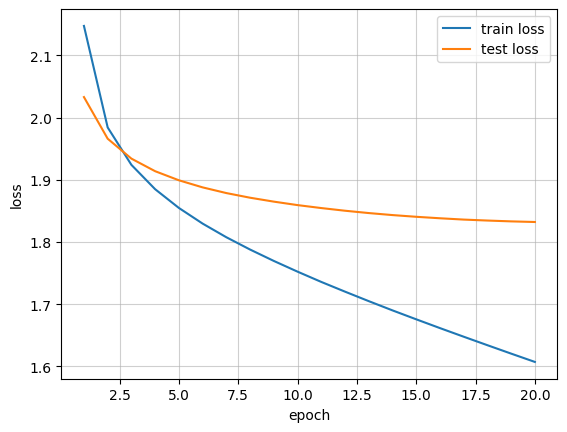

In [40]:
train_test_loss_plot(train_losses_hist, test_losses_hist)

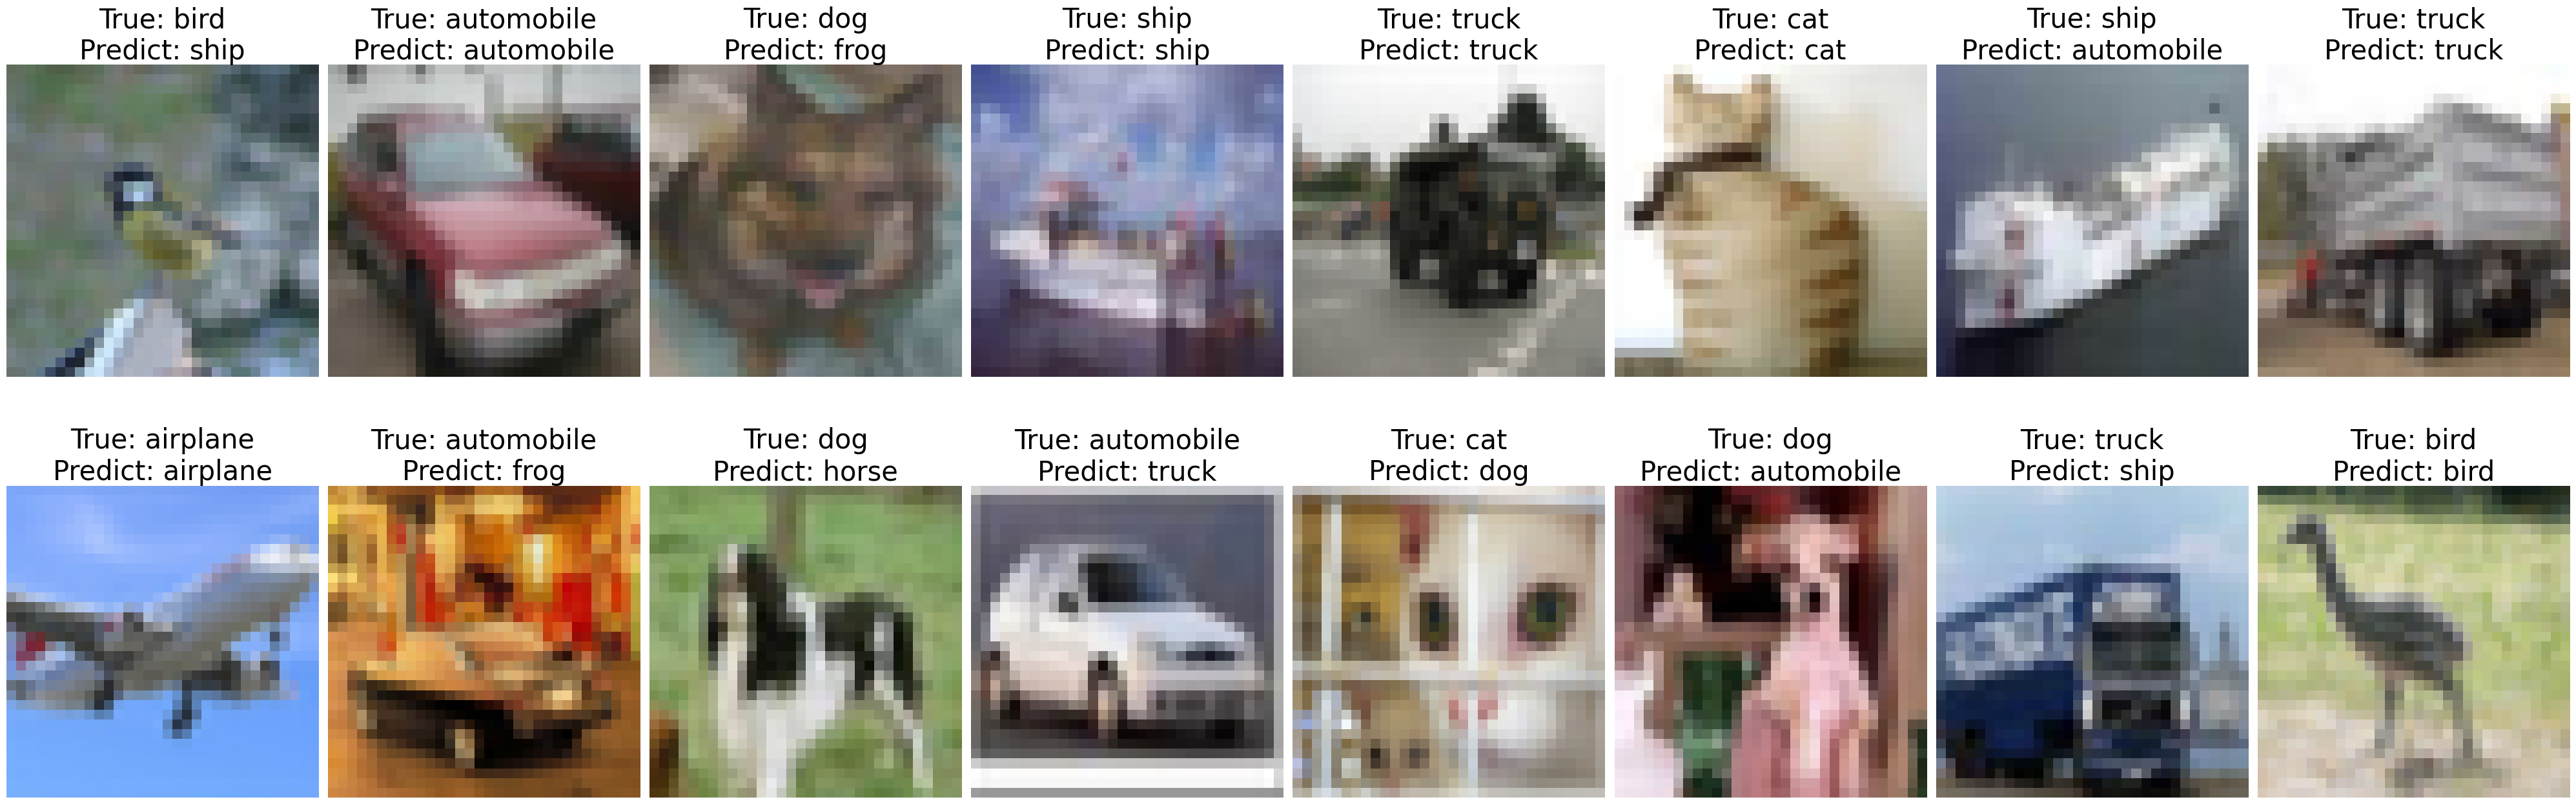

In [41]:
draw_image_predicts(hist_model, examples, hist_transform_func, true_labels)

## Входные данные: HOG

In [42]:
batch_size = 128
train_hog_dataloader, test_hog_dataloader = data_to_dataloader(X_train_hog, X_test_hog, y_train_hog, y_test_hog, batch_size)

In [43]:
class ClassificationHogModel(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(324, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits

In [44]:
hog_model = ClassificationHogModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(hog_model.parameters(), lr=1e-5)
train_losses_hog = []
test_losses_hog = []

In [45]:
num_epochs = 20

In [46]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(hog_model, loss_fn, optimizer, train_hog_dataloader, train_losses_hog)
    test_loop(hog_model, loss_fn, test_hog_dataloader, test_losses_hog)
    print('-' * 30)

Epoch 1
128/50048 | loss: 2.513333797454834
12928/50048 | loss: 2.1257505416870117
25728/50048 | loss: 1.9190423488616943
38528/50048 | loss: 1.7801412343978882
Test loss:  1.7779
              precision    recall  f1-score   support

           0       0.46      0.50      0.48      1000
           1       0.43      0.48      0.45      1000
           2       0.34      0.22      0.26      1000
           3       0.25      0.18      0.21      1000
           4       0.32      0.32      0.32      1000
           5       0.30      0.39      0.34      1000
           6       0.37      0.55      0.44      1000
           7       0.44      0.28      0.34      1000
           8       0.41      0.43      0.42      1000
           9       0.47      0.42      0.45      1000

    accuracy                           0.38     10000
   macro avg       0.38      0.38      0.37     10000
weighted avg       0.38      0.38      0.37     10000

------------------------------
Epoch 2
128/50048 | loss: 1.91

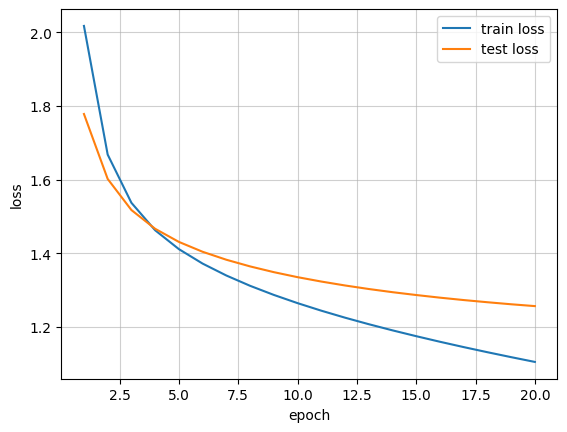

In [47]:
train_test_loss_plot(train_losses_hog, test_losses_hog)

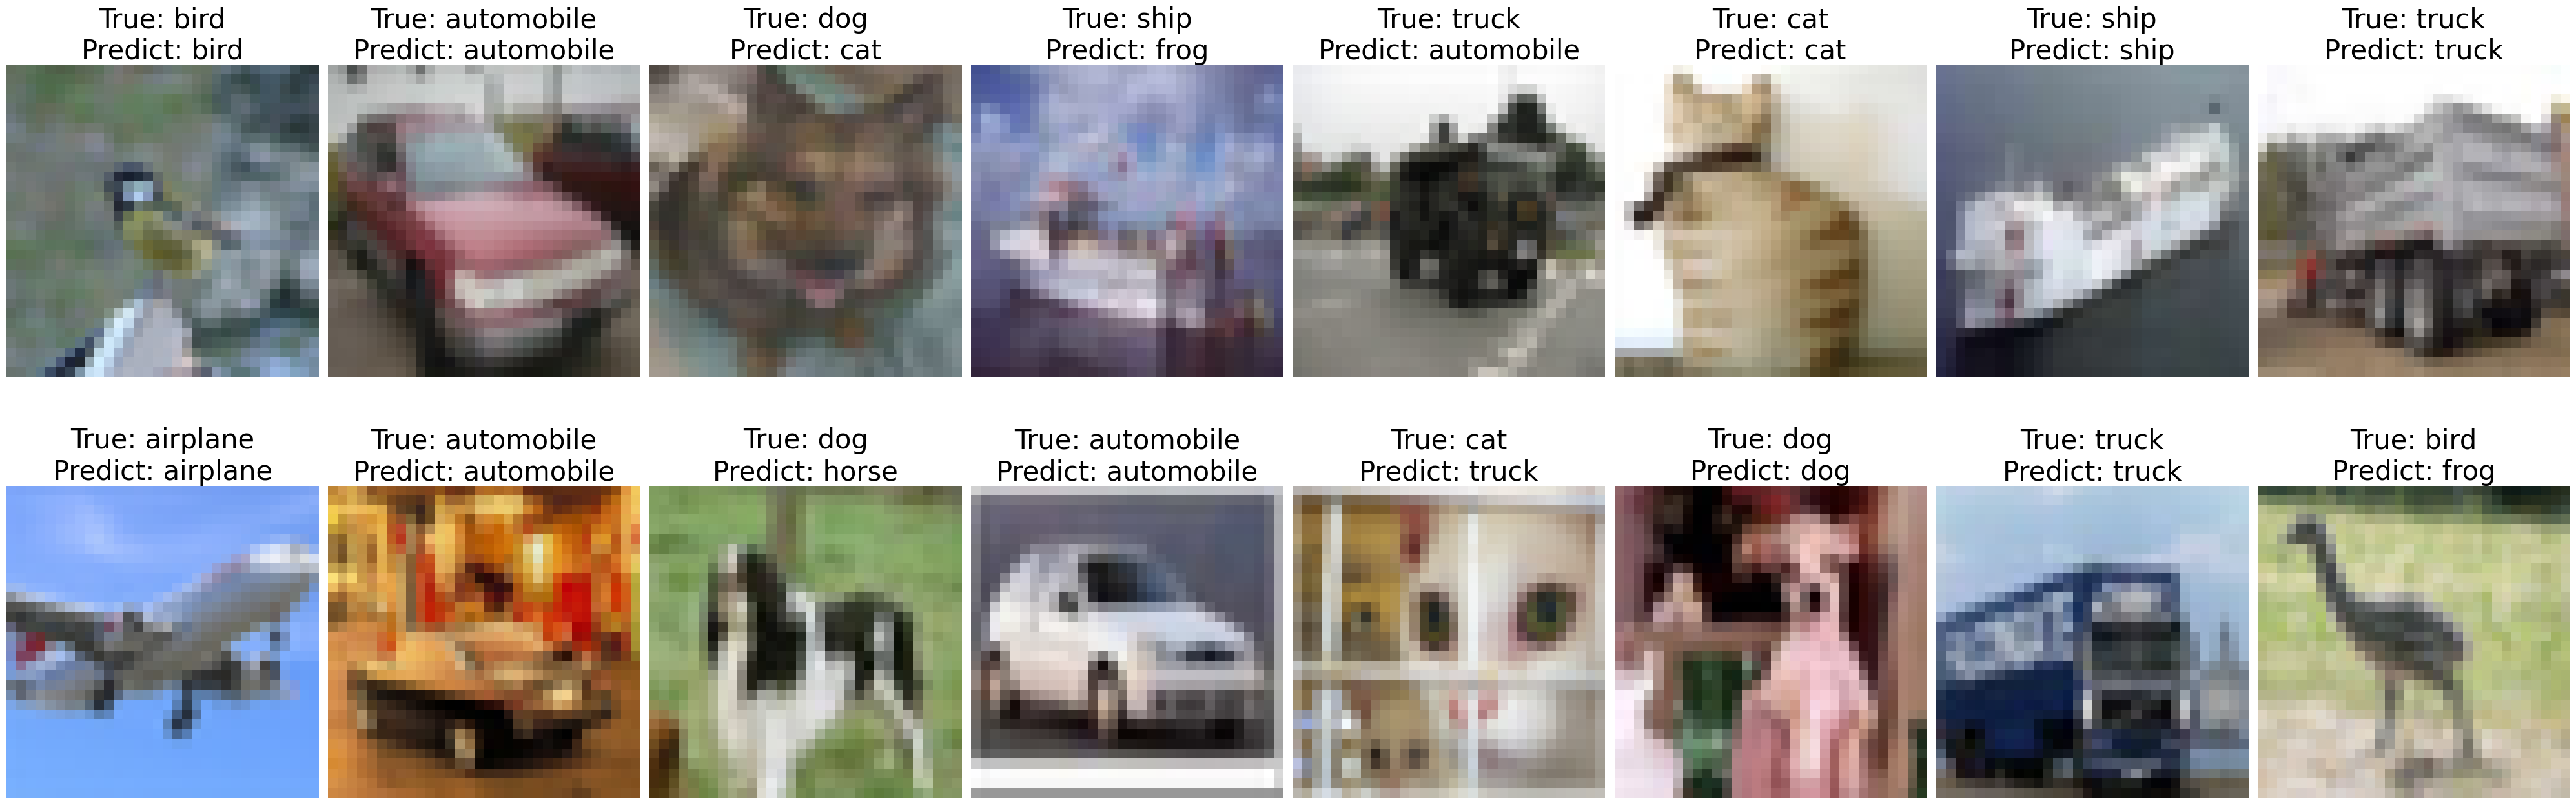

In [48]:
draw_image_predicts(hog_model, examples, hog_transform_func, true_labels)

# Задание 3. Классификация изображений сверточной нейросетью

In [92]:
class ConvClassificationModel(nn.Module):
    def __init__(self, h=32, w=32, num_classes=10):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ELU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ELU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ELU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(32 * 16 * 16, 512),
            nn.BatchNorm1d(512),
            nn.ELU(),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.conv_stack(x)
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [93]:
conv_model = ConvClassificationModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(conv_model.parameters(), lr=1e-5)
train_losses_conv = []
test_losses_conv = []

In [94]:
num_epochs = 20

In [95]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(conv_model, loss_fn, optimizer, train_dataloader, train_losses_conv)
    test_loop(conv_model, loss_fn, test_dataloader, test_losses_conv)
    print('-' * 30)

Epoch 1
128/50048 | loss: 2.3259198665618896
12928/50048 | loss: 1.5430197715759277
25728/50048 | loss: 1.6047289371490479
38528/50048 | loss: 1.3984489440917969
Test loss:  1.3737
              precision    recall  f1-score   support

           0       0.56      0.61      0.59      1000
           1       0.65      0.56      0.61      1000
           2       0.43      0.37      0.40      1000
           3       0.40      0.30      0.34      1000
           4       0.47      0.42      0.44      1000
           5       0.43      0.47      0.45      1000
           6       0.51      0.72      0.60      1000
           7       0.60      0.53      0.56      1000
           8       0.62      0.66      0.64      1000
           9       0.54      0.61      0.57      1000

    accuracy                           0.52     10000
   macro avg       0.52      0.52      0.52     10000
weighted avg       0.52      0.52      0.52     10000

------------------------------
Epoch 2
128/50048 | loss: 1.3

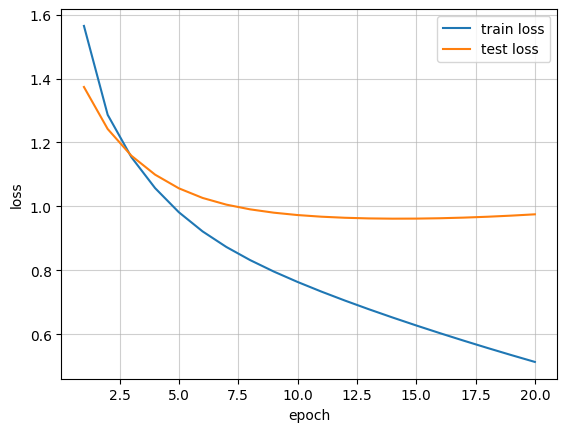

In [96]:
train_test_loss_plot(train_losses_conv, test_losses_conv)

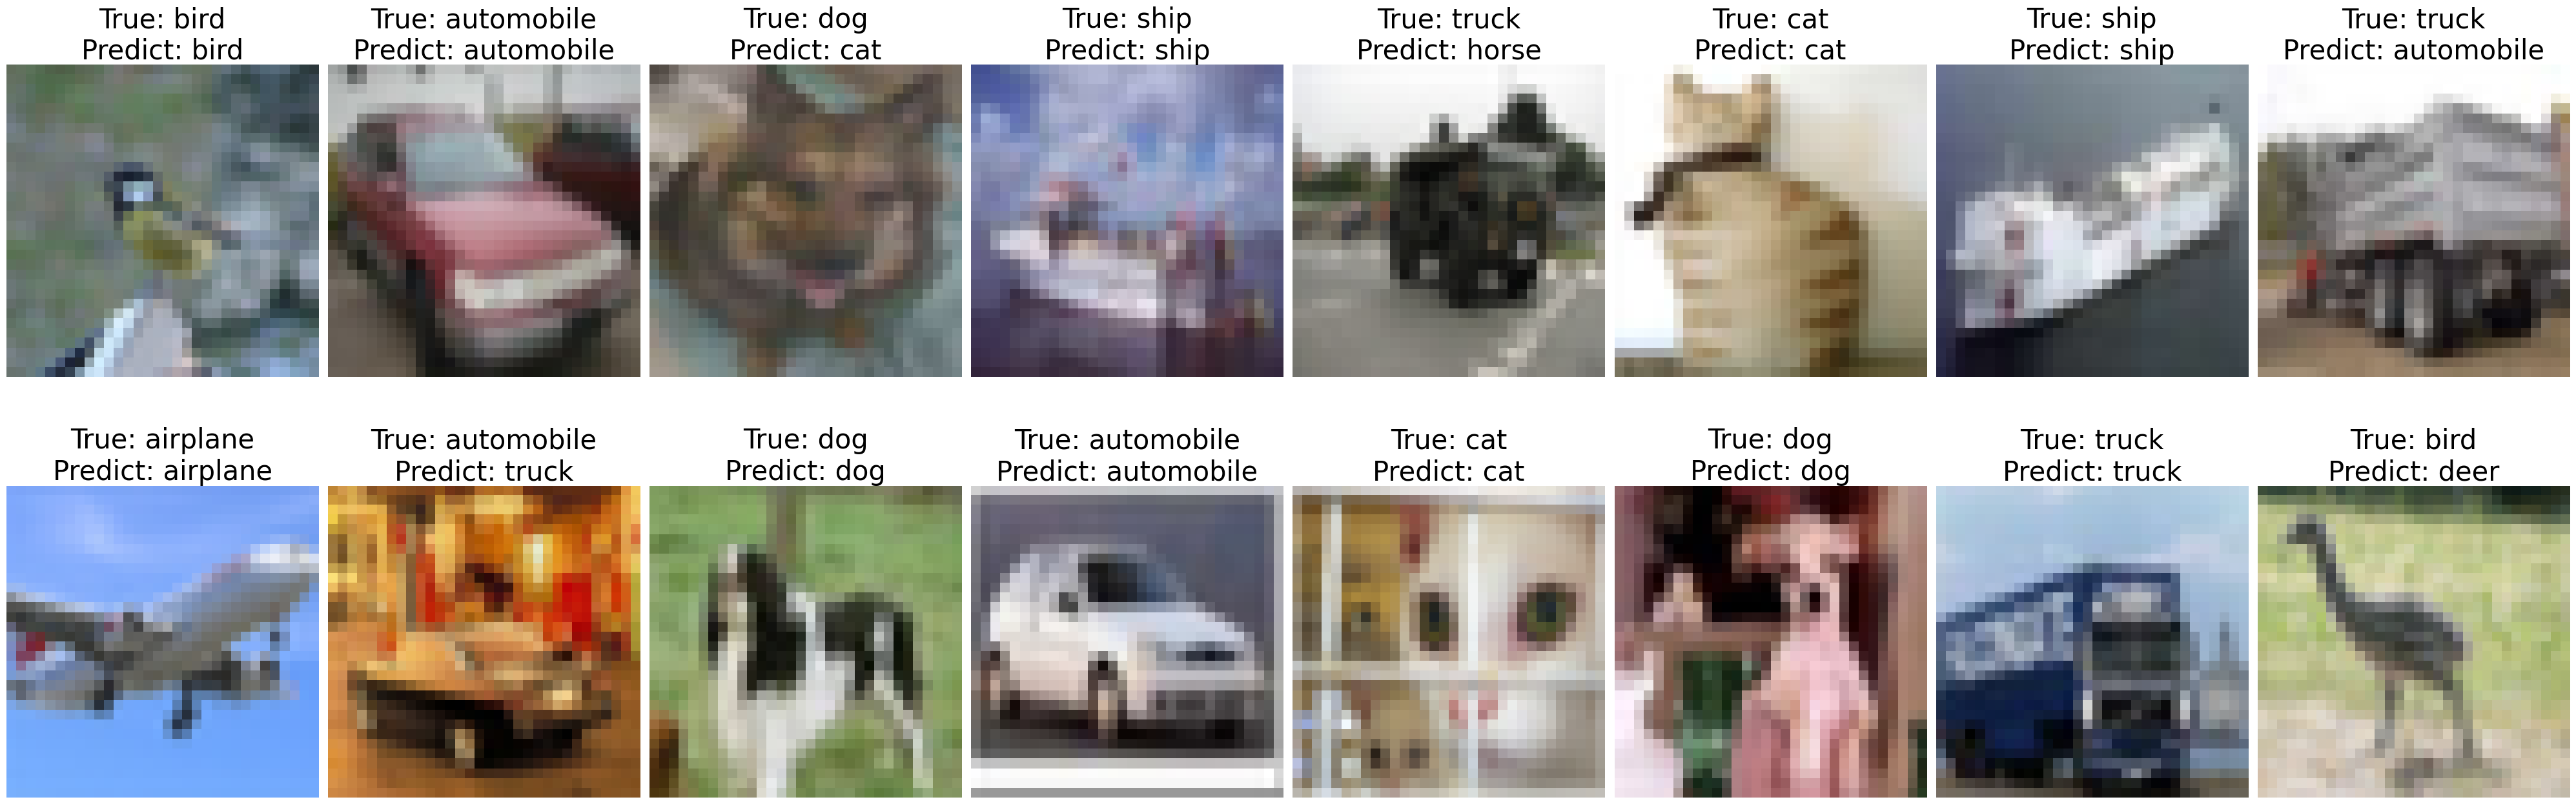

In [97]:
draw_image_predicts(conv_model, examples, transform, true_labels)